# CPW parametric amplifiers: layout and circuit models

::::{admonition} Required extras
:class: tip

Needs `models` and the external
[VACASK](https://codeberg.org/arpadbuermen/VACASK) simulator:
`uv sync --extra models` (or `pip install "qpdk[models]"`). Install VACASK,
put `vacask` on `PATH` or set `VACASK`; it compiles Verilog-A with the bundled
`openvaf-r`, and Linux also needs `binutils`. See the
{ref}`extras reference <notebook-extras>`.
::::

A flux-pumped JPA uses a SQUID to modulate the resonance of a distributed
resonator at twice its frequency
{cite:p}`yamamotoFluxdrivenJosephsonParametric2008`. To simulate that in a
circuit solver, represent the linear part as a subcircuit and solve the
pumped nonlinear part with harmonic balance
{cite:p}`kundertSimulationNonlinearCircuits1986,maasNonlinearMicrowaveRF2003`.

This notebook checks the models with released VACASK. It compares two
line models against SAX. It then uses them to measure resonance against flux,
the single-mode threshold, gain against pump amplitude, and the higher-mode
conversion that breaks the simple signal-idler balance. The
{doc}`TWPA notebook <josephsoncircuits_twpa>`
covers traveling-wave amplification. The
{doc}`lumped companion <vacask_lumped_parametric_amplifier>`
runs lumped Kerr and SQUID examples.

The analyses differ in what they assume. AC linearizes the circuit around its
DC operating point. ACSP returns S-parameters with the pump off. HB finds the
nonlinear periodic pump. HBAC finds infinitesimal signal and idler waves
around that pump. The {ref}`vacask-analysis-guide` in the lumped companion
compares them in detail.

In [1]:
import sys

if "google.colab" in sys.modules:
    import subprocess

    print("Running in Google Colab. Installing dependencies...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "qpdk[models] @ git+https://github.com/gdsfactory/quantum-rf-pdk.git",
    ])

In [2]:
import os
import time
from pathlib import Path

import jax
import jax.numpy as jnp
from jax.typing import ArrayLike
from matplotlib import font_manager, pyplot as plt
from matplotlib.collections import PolyCollection
from sax.models import rf

import qpdk.colormaps  # ruff: ignore[unused-import] - registers the style colormap
from qpdk import PDK, logger
from qpdk.cells.resonator import resonator
from qpdk.config import PATH
from qpdk.models.constants import Φ_0
from qpdk.models.cpw import get_cpw_dimensions, get_cpw_substrate_params
from qpdk.models.junction import squid_junction
from qpdk.simulation.vacask import (
    Netlist,
    Vacask,
    VacaskError,
    cpw_tline_params,
    format_value,
    vector_fit,
    vector_fit_subckt,
)

# Agg suppresses notebook figure outputs in headless CI.
if "ipykernel" in sys.modules:
    from IPython import get_ipython
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    if (ipython := get_ipython()) is not None:
        ipython.run_line_magic("matplotlib", "inline")
        set_matplotlib_formats("png", "svg")

jax.config.update("jax_enable_x64", True)
PDK.activate()

# The checkout stylesheet is absent from installed wheels.
for _style in (PATH.docs / "qpdk.mplstyle", "qpdk"):
    try:
        plt.style.use(_style)
    except OSError:
        continue
    break

# The stylesheet names fonts that only the docs build ships; register them so
# they resolve without docs/ipython_config.py.
_font_dir = os.environ.get("QPDK_DOCS_FONTS_DIR")
for _fonts in (Path(_font_dir) if _font_dir else None, PATH.repo / "build/docs-fonts"):
    if _fonts is not None and _fonts.is_dir():
        for _font in sorted(_fonts.iterdir()):
            if _font.suffix in {".otf", ".ttf"}:
                font_manager.fontManager.addfont(str(_font))
        break

## Finding VACASK

{meth}`Vacask.find() <qpdk.simulation.vacask.Vacask.find>` checks the
`VACASK`/`QPDK_VACASK` environment variables and `PATH`. The notebook stops
if the binary is missing.

In [3]:
try:
    vacask = Vacask.find()
except VacaskError as error:
    print(error)
    raise SystemExit(
        "VACASK is not installed; skipping the rest of this notebook."
    ) from None
print(f"Using VACASK at {vacask.binary}")

Using VACASK at <runtime>


Every netlist uses `tolscale=1e-6 reltol=1e-6`. The default tolerances shift
the gain by more than the differences resolved here. Port conventions:

- A port is a Norton source $I_\text{s}$ in parallel with $R=50\,\Omega$.
  So $V_\text{inc}=I_\text{s}R/2$ and $\Gamma=2V/(I_\text{s}R)-1$
  {cite:p}`m.pozarMicrowaveEngineering2012`.
- VACASK reports a `sine` source of amplitude $A$ as $-\text{j}A$, so the
  incident HB phasor is $-\text{j}I_\text{s}R/2$.
- `hbac` writes the response at $f_\text{s}+k f_\text{p}$ as `node;k`.

In [4]:
R_PORT = 50.0
I_SIG = 1e-9
OPTIONS = "options tolscale=1e-6 reltol=1e-6"
SMALL_SIGNAL = f"mag=1e-9 spur={{[0]}} smag=[{I_SIG}]"


def db(x: ArrayLike) -> jax.Array:
    r"""Power gain in dB of a wave amplitude ratio, :math:`20\log_{10}|A|`. See :cite:p:`m.pozarMicrowaveEngineering2012`."""
    return 20 * jnp.log10(jnp.abs(x))


def reflection(v: ArrayLike, source_current: float) -> jax.Array:
    r"""Reflection coefficient of a Norton port from its node voltage.

    Uses :math:`\Gamma=2V/(I_\text{s}R)-1`
    :cite:p:`m.pozarMicrowaveEngineering2012`.

    Returns:
        Complex reflected wave amplitude divided by the incident amplitude.
    """
    return 2 * jnp.asarray(v) / (source_current * R_PORT) - 1


def conversion(v: ArrayLike, source_current: float) -> jax.Array:
    r"""Conversion gain into a sideband other than the one driven.

    The sideband amplitude is :math:`2V/(I_\text{s}R)`, as in
    frequency-conversion analysis :cite:p:`maasNonlinearMicrowaveRF2003`.

    Returns:
        Complex sideband wave amplitude divided by the incident amplitude.
    """
    return 2 * jnp.asarray(v) / (source_current * R_PORT)


def show_plot() -> None:
    """Show the current figure with Outfit titles, as the docs config does."""
    fig = plt.gcf()
    for text in [ax.title for ax in fig.axes] + list(fig.texts):
        if text.get_text():
            text.set_fontfamily("Outfit")
            text.set_fontweight("bold")
    plt.show()

## SQUID-terminated quarter-wave resonator

Following {cite:t}`yamamotoFluxdrivenJosephsonParametric2008`, a 4680 µm CPW
($\lambda/4$ at 6.5 GHz) is shorted through the SQUID. It is coupled to the
port by $C_\text{c}=20$ fF, using the PDK `cpw` cross-section. The pump
modulates the SQUID flux at $f_\text{p}\approx2f_0$. A signal at
$f_\text{s}$ is amplified with an idler at $f_\text{p}-f_\text{s}$. This is
three-wave mixing.

The symmetric SQUID is one junction with
$I_\text{c,tot}\cos(\pi\Phi/\Phi_0)$. This neglects loop inductance, valid for
$\beta_L=2L_\text{loop}I_\text{c}/\Phi_0\ll1$
{cite:p}`tescheDcSQUIDNoise1977`. Its flux terminal is driven in units of
$\Phi_0$.

(vacask-cpw-layout)=
## Use the same geometry for layout and models

Make a QPDK meander with the `cpw` cross-section. Read its realized centreline length after grid snapping. Use that length and cross-section for both the SAX line model and VACASK's line impedance and delay. Here the realized length is 4680 µm, the strip width is 10 µm and the gap is 6 µm.

The two end ports connect to the ideal coupling capacitor and SQUID in the circuit. Those end devices are not drawn here. The line model uses a uniform cross-section approximation {cite:p}`simonsCoplanarWaveguideCircuits2001,ghioneAnalyticalFormulasCoplanar1984`. It does not include coupling between meanders, bend corrections or end-pad parasitics. For those effects, export this geometry to a field solver as in the {doc}`CPW field simulation notebook <comsol_cpw_resonator>`.

The plot below comes from the layout polygons. Changing the cross-section or length changes both the geometry and the model inputs.

2026-10-21 10:06:40.902 | INFO     | __main__:<module>:14 - Layout length 4680.0 µm, Z0 49.3128 Ω, delay 38.4457 ps


findfont: Failed to find font weight bold, now using 400.


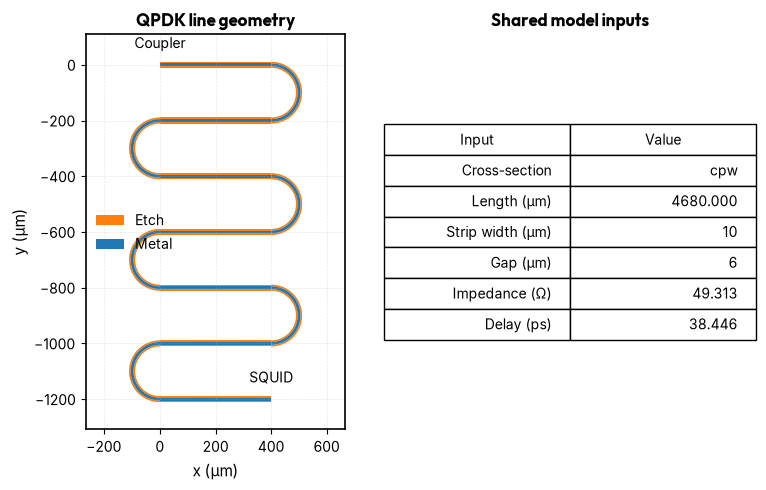

In [5]:
LINE_CROSS_SECTION = "cpw"
line_layout = resonator(
    length=4680.0,
    meanders=6,
    cross_section=LINE_CROSS_SECTION,
    open_start=False,
    open_end=False,
)
LENGTH = float(line_layout.info["length"])
C_COUPLING = 20e-15
width, gap = get_cpw_dimensions(LINE_CROSS_SECTION)
h_sub, t_metal, ep_r, _ = get_cpw_substrate_params()
z0_line, td_line = cpw_tline_params(LENGTH, cross_section=LINE_CROSS_SECTION)
logger.info(
    "Layout length {} µm, Z0 {:.4f} Ω, delay {:.4f} ps", LENGTH, z0_line, td_line * 1e12
)

fig, (ax_layout, ax_values) = plt.subplots(
    1, 2, figsize=(8, 5), gridspec_kw={"width_ratios": [1, 1.2]}
)
polygons = line_layout.get_polygons_points(by="name")
for layer_name, color, label in (
    ("M1_ETCH", "C1", "Etch"),
    ("M1_DRAW", "C0", "Metal"),
):
    ax_layout.add_collection(
        PolyCollection(
            polygons[layer_name], facecolor=color, edgecolor="none", label=label
        )
    )
for port_name, label in (("o1", "Coupler"), ("o2", "SQUID")):
    port = line_layout.ports[port_name]
    ax_layout.annotate(
        label, port.center, xytext=(0, 12), textcoords="offset points", ha="center"
    )
ax_layout.autoscale_view()
ax_layout.margins(0.25, 0.08)
ax_layout.set_aspect("equal")
ax_layout.set(xlabel="x (µm)", ylabel="y (µm)", title="QPDK line geometry")
ax_layout.legend(loc="center left", bbox_to_anchor=(0, 0.5))
ax_values.axis("off")
parameters = [
    ["Cross-section", LINE_CROSS_SECTION],
    ["Length (µm)", f"{LENGTH:.3f}"],
    ["Strip width (µm)", f"{width:g}"],
    ["Gap (µm)", f"{gap:g}"],
    ["Impedance (Ω)", f"{z0_line:.3f}"],
    ["Delay (ps)", f"{td_line * 1e12:.3f}"],
]
parameter_table = ax_values.table(
    cellText=parameters, colLabels=["Input", "Value"], loc="center"
)
parameter_table.auto_set_font_size(False)
parameter_table.set_fontsize(10)
parameter_table.scale(1, 1.8)
ax_values.set_title("Shared model inputs")
fig.tight_layout()
show_plot()

## A distributed line and a rational fit

- **Route A**: an ideal `tline_ideal` with $Z_0$ and delay from
  {func}`~qpdk.simulation.vacask.cpw_tline_params`. This is exact for a
  lossless TEM line.
- **Route B**: a rational fit of any linear SAX model by
  {func}`~qpdk.simulation.vacask.vector_fit` (vector fitting with passivity
  enforcement {cite:p}`gustavsenRationalApproximationFrequency1999`),
  emitted by {func}`~qpdk.simulation.vacask.vector_fit_subckt`.

Both are compared with SAX after renormalizing to 50 Ω through ABCD matrices
{cite:p}`m.pozarMicrowaveEngineering2012`. The loss tangent is zero, so all
three describe the same lossless line.

The line comparison and the fit check answer different questions. The CPW
dispersion comes from the SAX coplanar-waveguide model
{cite:p}`gopplCoplanarWaveguideResonators2008a`. The rational fit tests only
how well Route B reproduces that model.

In [6]:
def s_to_abcd(s: jax.Array, z0: float) -> jax.Array:
    """ABCD matrices of two-port S-matrices ``(..., 2, 2)`` referenced to ``z0``.

    Standard S-to-ABCD conversion :cite:p:`m.pozarMicrowaveEngineering2012`.

    Returns:
        ABCD matrices with the same leading axes as the input.
    """
    s11, s12, s21, s22 = s[..., 0, 0], s[..., 0, 1], s[..., 1, 0], s[..., 1, 1]
    a = ((1 + s11) * (1 - s22) + s12 * s21) / (2 * s21)
    b = z0 * ((1 + s11) * (1 + s22) - s12 * s21) / (2 * s21)
    c = ((1 - s11) * (1 - s22) - s12 * s21) / (2 * s21 * z0)
    d = ((1 - s11) * (1 + s22) + s12 * s21) / (2 * s21)
    return jnp.stack([jnp.stack([a, b], -1), jnp.stack([c, d], -1)], -2)


def abcd_to_s(abcd: jax.Array, z0: float) -> jax.Array:
    """Two-port S-matrices of ABCD matrices, referenced to ``z0``.

    Standard ABCD-to-S conversion :cite:p:`m.pozarMicrowaveEngineering2012`.

    Returns:
        Two-port S-matrices with the same leading axes as the input.
    """
    a, b, c, d = abcd[..., 0, 0], abcd[..., 0, 1], abcd[..., 1, 0], abcd[..., 1, 1]
    den = a + b / z0 + c * z0 + d
    s11 = (a + b / z0 - c * z0 - d) / den
    s12 = 2 * (a * d - b * c) / den
    s22 = (-a + b / z0 - c * z0 + d) / den
    return jnp.stack([jnp.stack([s11, s12], -1), jnp.stack([2 / den, s22], -1)], -2)


def coupled_line_abcd(f: jax.Array) -> jax.Array:
    """ABCD matrix of the coupling capacitor followed by the CPW.

    The line is the SAX coplanar-waveguide model
    :cite:p:`gopplCoplanarWaveguideResonators2008a`. The coupling capacitor is
    a series impedance.

    Returns:
        ABCD matrices of the series coupling capacitor and line.
    """
    line = rf.coplanar_waveguide(
        f=f,
        length=LENGTH,
        width=width,
        gap=gap,
        thickness=t_metal,
        substrate_thickness=h_sub,
        ep_r=ep_r,
        tand=0.0,
    )
    s = jnp.stack(
        [
            jnp.stack([line["o1", "o1"], line["o1", "o2"]], -1),
            jnp.stack([line["o2", "o1"], line["o2", "o2"]], -1),
        ],
        -2,
    )
    one, zero = jnp.ones_like(f), jnp.zeros_like(f)
    z_cap = 1 / (2j * jnp.pi * f * C_COUPLING)
    abcd_cap = jnp.stack([jnp.stack([one, z_cap], -1), jnp.stack([zero, one], -1)], -2)
    return abcd_cap @ s_to_abcd(s, z0_line)


def coupled_line_sdict(f: jax.Array) -> dict:
    """50 Ω S-parameters of the coupling capacitor followed by the CPW."""
    s = abcd_to_s(coupled_line_abcd(f), R_PORT)
    return {(f"o{i + 1}", f"o{j + 1}"): s[:, i, j] for i in range(2) for j in range(2)}


f_fit = jnp.linspace(10e6, 70e9, 3500)
start = time.perf_counter()
fit = vector_fit(coupled_line_sdict(f_fit), f_fit, ports=["o1", "o2"])
reference_fit = coupled_line_sdict(f_fit)
fit_error = max(
    jnp.max(jnp.abs(fit.get_model_response(i, j, f_fit) - reference_fit[pi, pj]))
    for i, pi in enumerate(("o1", "o2"))
    for j, pj in enumerate(("o1", "o2"))
)
pole_count = 0 if fit.poles is None else len(fit.poles)
print(
    f"rational fit: {pole_count} poles, max |ΔS| = {fit_error:.1e}, "
    f"{time.perf_counter() - start:.1f} s"
)

<runtime> RuntimeWarning: divide by zero encountered in matmul
  prod_neg = np.matmul(np.matmul(B, inv_neg), C)
<runtime> RuntimeWarning: overflow encountered in matmul
  prod_neg = np.matmul(np.matmul(B, inv_neg), C)
<runtime> RuntimeWarning: invalid value encountered in matmul
  prod_neg = np.matmul(np.matmul(B, inv_neg), C)
<runtime> RuntimeWarning: divide by zero encountered in matmul
  prod_pos = np.matmul(np.matmul(B, inv_pos), C)
<runtime> RuntimeWarning: overflow encountered in matmul
  prod_pos = np.matmul(np.matmul(B, inv_pos), C)
<runtime> RuntimeWarning: invalid value encountered in matmul
  prod_pos = np.matmul(np.matmul(B, inv_pos), C)
<runtime> RuntimeWarning: divide by zero encountered in matmul
  P = np.matmul(A - prod_neg, A - prod_pos)
<runtime> RuntimeWarning: overflow encountered in matmul
  P = np.matmul(A - prod_neg, A - prod_pos)
<runtime> RuntimeWarning: invalid value encountered in matmul
  P = np.matmul(A - prod_neg, A - prod_pos)
<runtime> UserWarning: The f

rational fit: 11 poles, max |ΔS| = 2.3e-03, 0.6 s


Route A is a hand-written subcircuit. Route B is generated. Both have
terminals `p1` (port side) and `p2` (far end of the line).

The check uses ACSP. It gives the cold multiport S-parameters at the fixed DC
bias with small port excitations. No pump is solved.

In [7]:
ROUTE_A = f"""
    subckt ccline (p1 p2)
      cc (p1 1) capacitor c={C_COUPLING}
      t1 (1 0 p2 0) tline_ideal z0={z0_line} td={td_line}
    ends
"""
ROUTE_B = vector_fit_subckt(fit, "ccline")
print("\n".join(ROUTE_B.splitlines()[:12]), "\n...")

// Rational model of ports o1, o2, 11 poles
subckt ccline (p1 p2)
  model vccs vccs
  r1 (p1 0) resistor r=50
  g2 (0 p1 b0 0) vccs gain=0.04
  r3 (a0 0) resistor r=1
  g4 (0 a0 p1 0) vccs gain=1
  g5 (0 a0 b0 0) vccs gain=-1
  r6 (b0 0) resistor r=1
  r7 (p2 0) resistor r=50
  g8 (0 p2 b1 0) vccs gain=0.04
  r9 (a1 0) resistor r=1 
...


s(1,1): Route A max|ΔS| = 8.0e-16, Route B max|ΔS| = 1.1e-03
s(2,1): Route A max|ΔS| = 6.1e-16, Route B max|ΔS| = 1.2e-03
s(2,2): Route A max|ΔS| = 3.8e-15, Route B max|ΔS| = 1.1e-03


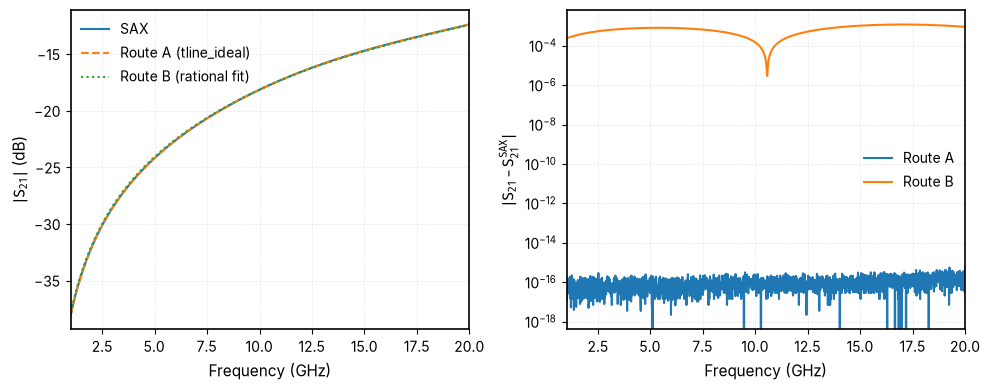

In [8]:
f_check = jnp.linspace(1e9, 20e9, 1901)
LINE_LOADS = ["capacitor.osdi", "resistor.osdi", "tline_ideal.osdi"]
ports = ["vp1", "rp1", "vp2", "rp2"]


def two_port_netlist(route: str) -> Netlist:
    """S-parameters of the coupled line, Route A or Route B."""
    return Netlist(
        f"Coupled CPW, Route {route}",
        loads=LINE_LOADS,
        subckts=[ROUTE_A if route == "A" else ROUTE_B],
        circuit=f"""
            model vsource vsource
            model resistor resistor
            model capacitor capacitor
            model tline_ideal tline_ideal

            x1 (1 2) ccline
            vp1 (a1 0) vsource dc=0
            rp1 (a1 1) resistor r={R_PORT}
            vp2 (a2 0) vsource dc=0
            rp2 (a2 2) resistor r={R_PORT}
        """,
        control=f"""
            {OPTIONS}
            analysis sp acsp ports={format_value(ports)} values={format_value(f_check)}
        """,
    )


results = {route: vacask.run(two_port_netlist(route))["sp"] for route in "AB"}
reference = coupled_line_sdict(f_check)
for key, (i, j) in {"s(1,1)": (0, 0), "s(2,1)": (1, 0), "s(2,2)": (1, 1)}.items():
    ref = reference[f"o{i + 1}", f"o{j + 1}"]
    errors = {
        route: jnp.max(jnp.abs(jnp.asarray(results[route][key]) - ref))
        for route in "AB"
    }
    print(
        f"{key}: Route A max|ΔS| = {errors['A']:.1e}, "
        f"Route B max|ΔS| = {errors['B']:.1e}"
    )

fig, (ax, ax_err) = plt.subplots(1, 2, figsize=(10, 4))
ax.plot(f_check / 1e9, db(reference["o2", "o1"]), label="SAX")
ax.plot(f_check / 1e9, db(results["A"]["s(2,1)"]), "--", label="Route A (tline_ideal)")
ax.plot(f_check / 1e9, db(results["B"]["s(2,1)"]), ":", label="Route B (rational fit)")
ax.set_xlabel("Frequency (GHz)")
ax.set_ylabel(r"$|S_{21}|$ (dB)")
ax.legend()
for route in "AB":
    error = jnp.abs(jnp.asarray(results[route]["s(2,1)"]) - reference["o2", "o1"])
    ax_err.semilogy(f_check / 1e9, error, label=f"Route {route}")
ax_err.set_xlabel("Frequency (GHz)")
ax_err.set_ylabel(r"$|S_{21} - S_{21}^\text{SAX}|$")
ax_err.legend()
fig.tight_layout()
show_plot()

Route A matches SAX to rounding error. Route B differs by about $10^{-3}$.
That is acceptable for linear S-parameters, but not for a high-Q resonator.

## Resonance versus flux

The SQUID has $I_\text{c,tot}=4$ µA. The resonance is the peak of the
reflection group delay, $\tau=-\text{d}\arg\Gamma/\text{d}\omega$
{cite:p}`m.pozarMicrowaveEngineering2012`. For a lossless, overcoupled
one-port resonator $\tau_\text{peak}=4/\kappa$, so the width
$4/(2\pi\tau_\text{peak})$ is the linewidth only in that case
{cite:p}`gopplCoplanarWaveguideResonators2008a`. The SAX reference terminates
the coupled-line ABCD matrix with the admittance of
{func}`~qpdk.models.junction.squid_junction` {cite:p}`tescheDcSQUIDNoise1977`.

AC linearizes the circuit around its DC operating point. With zero pump, it
gives the unpumped resonance.

Φ = 0.00 Φ0: VACASK 6.08328 GHz, SAX 6.08328 GHz
Φ = 0.10 Φ0: VACASK 6.07064 GHz, SAX 6.07064 GHz
Φ = 0.20 Φ0: VACASK 6.02580 GHz, SAX 6.02580 GHz
Φ = 0.25 Φ0: VACASK 5.98322 GHz, SAX 5.98322 GHz
Φ = 0.30 Φ0: VACASK 5.91600 GHz, SAX 5.91600 GHz
Φ = 0.35 Φ0: VACASK 5.80267 GHz, SAX 5.80267 GHz
Φ = 0.40 Φ0: VACASK 5.58455 GHz, SAX 5.58455 GHz


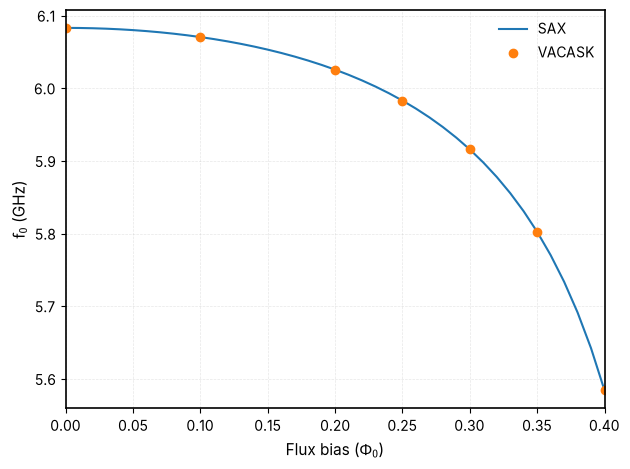

In [9]:
IC_SQUID = 4e-6


def cpw_jpa_netlist(
    control: str,
    *,
    route: str = "A",
    flux: float = 0.3,
    pump: float = 0.0,
    f_pump: float = 1e9,
) -> Netlist:
    """Quarter-wave CPW JPA netlist using Route A or Route B for the line."""
    return Netlist(
        "Quarter-wave CPW JPA",
        loads=[*LINE_LOADS, "squid.va"],
        subckts=[ROUTE_A if route == "A" else ROUTE_B],
        circuit=f"""
            model isource isource
            model vsource vsource
            model resistor resistor
            model capacitor capacitor
            model tline_ideal tline_ideal
            model squid squid

            iin (0 in) isource dc=0 {SMALL_SIGNAL}
            rport (in 0) resistor r={R_PORT}
            x1 (in 2) ccline
            s1 (2 0 fl) squid ic_tot={IC_SQUID}
            vfl (fl 0) vsource type="sine" sinedc={flux} ampl={pump} freq={f_pump}
        """,
        control=f"{OPTIONS}\n{control}",
    )


def resonance(f: jax.Array, gamma: jax.Array) -> tuple[jax.Array, jax.Array]:
    r"""Peak-delay frequency and 4/(2π tau).

    Group delay is :math:`-\text{d}\arg\Gamma/\text{d}\omega`
    :cite:p:`m.pozarMicrowaveEngineering2012`. The second value is a linewidth
    only for a lossless one-port resonator
    :cite:p:`gopplCoplanarWaveguideResonators2008a`.

    Returns:
        Peak-delay frequency and effective delay width, both in Hz.
    """
    grad = jnp.gradient(jnp.unwrap(jnp.angle(gamma)), 2 * jnp.pi * f)
    tau = -jnp.asarray(grad[0] if isinstance(grad, list) else grad)
    k = tau.argmax()
    return f[k], 4 / tau[k] / (2 * jnp.pi)


def sax_reflection(f: jax.Array, flux: float) -> jax.Array:
    """Reflection of the SAX coupled line terminated by the SAX SQUID.

    The SQUID admittance follows :cite:p:`tescheDcSQUIDNoise1977`.

    Returns:
        Complex port reflection coefficients.
    """
    abcd = coupled_line_abcd(f)
    squid = squid_junction(
        f=f, ic_tot=IC_SQUID, capacitance=0.0, resistance=1e12, flux=flux * Φ_0
    )
    y_load = 1 / squid["o1", "o1"] - 1
    z_in = (abcd[:, 0, 0] / y_load + abcd[:, 0, 1]) / (
        abcd[:, 1, 0] / y_load + abcd[:, 1, 1]
    )
    return (z_in - R_PORT) / (z_in + R_PORT)


fluxes = [0.0, 0.1, 0.2, 0.25, 0.3, 0.35, 0.4]
ac = vacask.run(
    cpw_jpa_netlist(f"""
        sweep flux instance="vfl" parameter="sinedc" values={format_value(fluxes)}
        analysis ac1 ac from=5.4e9 to=6.2e9 mode="lin" points=160001
    """)
)["ac1"]
f_grid = jnp.linspace(5.4e9, 6.2e9, 160001)
f_res = jnp.array([
    resonance(jnp.asarray(g["frequency"].real), reflection(g["in"], I_SIG))[0]
    for g in ac.split("flux")
])
f_sax = jnp.array([
    resonance(f_grid, sax_reflection(f_grid, flux))[0] for flux in fluxes
])
for flux, f0, f0_sax in zip(fluxes, f_res, f_sax, strict=True):
    print(f"Φ = {flux:.2f} Φ0: VACASK {f0 / 1e9:.5f} GHz, SAX {f0_sax / 1e9:.5f} GHz")

fluxes_fine = jnp.linspace(0, 0.4, 41)
f_sax_fine = jnp.array([
    resonance(f_grid, sax_reflection(f_grid, flux))[0] for flux in fluxes_fine
])
fig, ax = plt.subplots()
ax.plot(fluxes_fine, f_sax_fine / 1e9, "-", label="SAX")
ax.plot(fluxes, f_res / 1e9, "o", label="VACASK")
ax.set_xlabel(r"Flux bias ($\Phi_0$)")
ax.set_ylabel(r"$f_0$ (GHz)")
ax.legend()
show_plot()

## Operating point and the single-mode threshold

For $\omega_0(t)=\omega_0+\delta\omega\cos(2\omega_0t)$, single-mode theory
{cite:p}`royIntroductionParametricAmplification2016` gives the threshold
$\delta\omega=\kappa$ and the center gain

```{math}
:label: eq:vacask-3wm-gain
G_0 = \left(\frac{1 + r^2}{1 - r^2}\right)^2,
\qquad r = \frac{\delta\omega}{\kappa}
      = \frac{|\text{d}f_0/\text{d}\Phi|\,\Phi_\text{p}}{\kappa / 2\pi}.
```

We measure $f_0$, $\kappa$ and $\text{d}f_0/\text{d}\Phi$ at
$\Phi=0.3\,\Phi_0$ from AC sweeps. These runs have no pump, so the delay gives
the unpumped linewidth.

In [10]:
FLUX_BIAS = 0.3
operating_fluxes = [FLUX_BIAS - 1e-3, FLUX_BIAS, FLUX_BIAS + 1e-3]
ac = vacask.run(
    cpw_jpa_netlist(f"""
        sweep flux instance="vfl" parameter="sinedc" values={format_value(operating_fluxes)}
        analysis ac1 ac from=5.85e9 to=6.0e9 mode="lin" points=150001
    """)
)["ac1"]
operating = [
    resonance(jnp.asarray(g["frequency"].real), reflection(g["in"], I_SIG))
    for g in ac.split("flux")
]
(f_lo, _), (F0, KAPPA), (f_hi, _) = (tuple(map(float, x)) for x in operating)
DF_DPHI = (f_hi - f_lo) / 2e-3
PUMP_THRESHOLD = KAPPA / abs(DF_DPHI)
print(f"f0 = {F0 / 1e9:.6f} GHz, κ/2π = {KAPPA / 1e6:.3f} MHz, Q = {F0 / KAPPA:.0f}")
print(f"df0/dΦ = {DF_DPHI / 1e9:.4f} GHz/Φ0")
print(f"single-mode threshold Φp = {PUMP_THRESHOLD:.5f} Φ0")

f0 = 5.916001 GHz, κ/2π = 10.242 MHz, Q = 578
df0/dΦ = -1.7005 GHz/Φ0
single-mode threshold Φp = 0.00602 Φ0


## Gain versus pump amplitude

Pump at $f_\text{p}=2f_0$ below threshold and compare with
Eq. {eq}`eq:vacask-3wm-gain`.

`hbac` first solves the pump state, then finds the infinitesimal signal and
idler around it. By default it also solves the pump HB, so no separate HB run
is needed. See the {ref}`vacask-analysis-guide`.

At $f_\text{s}=f_\text{p}/2$ the signal and idler share one frequency and the
gain depends on the signal phase. The sweep skips that point, so each curve
is the phase-preserving gain of a slightly detuned signal.

r = 0.3: peak gain  1.26 dB (single-mode  1.57 dB), |S_ss|² - |S_is|² = 0.932
r = 0.5: peak gain  3.42 dB (single-mode  4.44 dB), |S_ss|² - |S_is|² = 0.786
r = 0.7: peak gain  6.53 dB (single-mode  9.31 dB), |S_ss|² - |S_is|² = 0.492
r = 0.8: peak gain  8.46 dB (single-mode 13.17 dB), |S_ss|² - |S_is|² = 0.241
r = 0.9: peak gain 10.70 dB (single-mode 19.58 dB), |S_ss|² - |S_is|² = -0.136


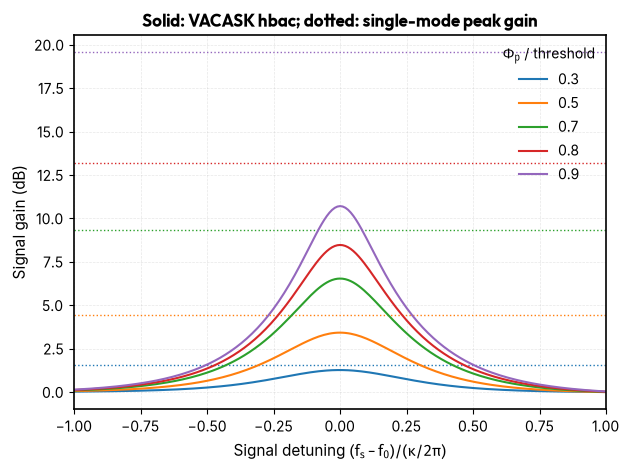

In [11]:
F_PUMP_CPW = 2 * F0
ratios = jnp.array([0.3, 0.5, 0.7, 0.8, 0.9])
# The 1.0013 keeps the 200-point grid off the degenerate point f_s = F0.
plot = vacask.run(
    cpw_jpa_netlist(
        f"""
        sweep pump instance="vfl" parameter="ampl" \\
            values={format_value(ratios * PUMP_THRESHOLD)}
        analysis hbac1 hbac freq=[{F_PUMP_CPW}] nharm=5 outspur={{[0],[-1]}} \\
            from={F0 - 1.0013 * KAPPA} to={F0 + 1.0013 * KAPPA} mode="lin" points=200
        """,
        f_pump=F_PUMP_CPW,
    )
)["hbac1"]

fig, ax = plt.subplots()
for group, r in zip(plot.split("pump"), ratios, strict=True):
    detuning = (jnp.asarray(group["frequency"].real) - F0) / KAPPA
    gain = db(reflection(group["in;0"], I_SIG))
    idler = db(conversion(group["in;-1"], I_SIG))
    k = jnp.argmin(jnp.abs(detuning))
    analytic = 20 * jnp.log10((1 + r**2) / (1 - r**2))
    print(
        f"r = {r:.1f}: peak gain {gain.max():5.2f} dB (single-mode {analytic:5.2f} dB), "
        f"|S_ss|² - |S_is|² = {10 ** (gain[k] / 10) - 10 ** (idler[k] / 10):.3f}"
    )
    (line,) = ax.plot(detuning, gain, label=f"{r:.1f}")
    ax.axhline(float(analytic), color=line.get_color(), ls=":", lw=1)
ax.set_xlabel(r"Signal detuning $(f_\text{s} - f_0)/(\kappa/2\pi)$")
ax.set_ylabel("Signal gain (dB)")
ax.legend(title=r"$\Phi_\text{p}$ / threshold")
ax.set_title("Solid: VACASK hbac; dotted: single-mode peak gain")
show_plot()

The CPW JPA gives less gain than Eq. {eq}`eq:vacask-3wm-gain`, and the
two-mode balance $|S_\text{ss}|^2-|S_\text{is}|^2$ falls below 1. Photons
leave through other sidebands. A quarter-wave line has modes near
$(2n+1)f_0$, spaced by $2f_0=f_\text{p}$. Every sideband
$|f_\text{s}+k f_\text{p}|$ then lands near a mode. For $k=+1$ and $k=-2$ that
is the $3\lambda/4$ mode, and for $k=+2$ and $k=-3$ the $5\lambda/4$ mode. The
pump couples the signal to these modes by frequency conversion ($k>0$) and by
further amplification ($k<0$). The SQUID's lumped inductance shifts the
higher modes slightly away from the odd harmonics, which limits this
conversion without removing it. A single-mode model cannot capture this.
{cite:t}`wustmannNondegenerateParametricResonance2017` analyse such intermode
processes.

A lossless pumped circuit conserves photons. That is the Manley-Rowe relation
{cite:p}`manleyGeneralPropertiesNonlinear1956`:

```{math}
:label: eq:vacask-manley-rowe
\sum_k \operatorname{sign}(f_k)\,|S_{k0}|^2\,\frac{f_\text{s}}{|f_k|} = 1,
\qquad f_k = f_\text{s} + k f_\text{p}.
```

Negative-frequency sidebands enter with a minus sign because they are
amplified, not converted {cite:p}`clerkIntroductionQuantumNoise2010`. The next
cell locates the $3\lambda/4$ mode and evaluates the sum over every sideband
that `hbac` retains.

modes between 12 and 22 GHz: 17.787 GHz
f_s + f_p at f_s = f_0: 17.748 GHz


r = 0.5: -3: -0.0003, -2: -0.0630, -1: -1.4071, +0: +2.1934, +1: +0.2758, +2: +0.0012; sum = 0.999998


r = 0.9: -3: -0.0250, -2: -1.7248, -1: -11.8197, +0: +11.6938, +1: +2.8344, +2: +0.0412, +3: +0.0001; sum = 0.999997


r = 0.9, nharm 5 -> 9: |ΔS_ss| = 1.3e-10


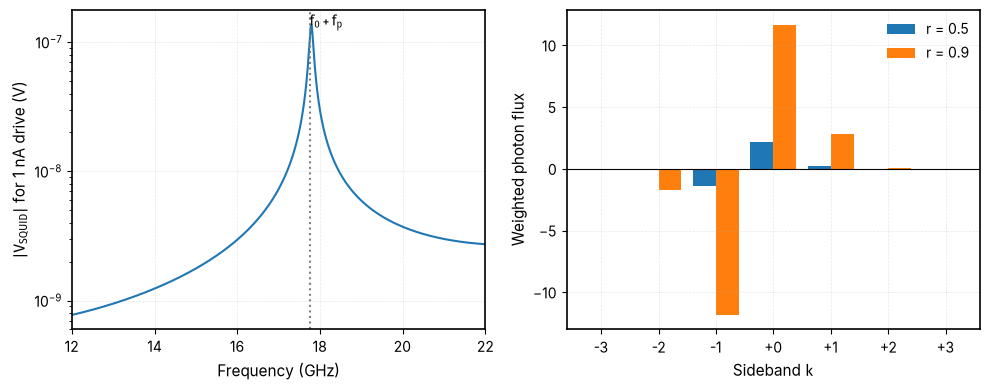

In [12]:
ac = vacask.run(
    cpw_jpa_netlist('analysis ac1 ac from=12e9 to=22e9 mode="lin" points=100001')
)["ac1"]
f_ac = jnp.asarray(ac["frequency"].real)
v_mode = jnp.abs(jnp.asarray(ac["2"]))
peaks = jnp.flatnonzero((v_mode[1:-1] > v_mode[:-2]) & (v_mode[1:-1] > v_mode[2:])) + 1
print(
    "modes between 12 and 22 GHz:", ", ".join(f"{f_ac[p] / 1e9:.3f} GHz" for p in peaks)
)
print(f"f_s + f_p at f_s = f_0: {(F0 + F_PUMP_CPW) / 1e9:.3f} GHz")

NHARM = 5
sidebands = list(range(-NHARM, NHARM + 1))
f_signal = F0 + 0.01 * KAPPA
photon_flux = {}
for r in (0.5, 0.9):
    group = vacask.run(
        cpw_jpa_netlist(
            f"""
            analysis hbac1 hbac freq=[{F_PUMP_CPW}] nharm={NHARM} \\
                outspur={format_value([[k] for k in sidebands])} values=[{f_signal}]
            """,
            pump=r * PUMP_THRESHOLD,
            f_pump=F_PUMP_CPW,
        )
    )["hbac1"]
    photons = []
    for k in sidebands:
        f_k = f_signal + k * F_PUMP_CPW
        amplitude = (reflection if k == 0 else conversion)(group[f"in;{k}"][0], I_SIG)
        photons.append(jnp.sign(f_k) * jnp.abs(amplitude) ** 2 * f_signal / abs(f_k))
    photon_flux[r] = jnp.array(photons)
    parts = ", ".join(
        f"{k:+d}: {p:+.4f}"
        for k, p in zip(sidebands, photons, strict=True)
        if abs(p) > 1e-4
    )
    print(f"r = {r}: {parts}; sum = {photon_flux[r].sum():.6f}")

refined = vacask.run(
    cpw_jpa_netlist(
        f"""
        analysis hbac1 hbac freq=[{F_PUMP_CPW}] nharm={NHARM + 4} \\
            outspur={{[0]}} values=[{f_signal}]
        """,
        pump=0.9 * PUMP_THRESHOLD,
        f_pump=F_PUMP_CPW,
    )
)["hbac1"]
basis_change = jnp.abs(
    reflection(refined["in;0"][0], I_SIG) - reflection(group["in;0"][0], I_SIG)
)
print(f"r = 0.9, nharm {NHARM} -> {NHARM + 4}: |ΔS_ss| = {basis_change:.1e}")

fig, (ax_modes, ax_bars) = plt.subplots(1, 2, figsize=(10, 4))
ax_modes.semilogy(f_ac / 1e9, v_mode)
ax_modes.axvline((F0 + F_PUMP_CPW) / 1e9, color="gray", ls=":")
ax_modes.annotate(
    r"$f_0 + f_\text{p}$",
    ((F0 + F_PUMP_CPW) / 1e9, 0.95),
    xycoords=("data", "axes fraction"),
)
ax_modes.set_xlabel("Frequency (GHz)")
ax_modes.set_ylabel(r"$|V_\text{SQUID}|$ for 1 nA drive (V)")
x = jnp.arange(len(sidebands))
for offset, (r, photons) in zip((-0.2, 0.2), photon_flux.items(), strict=True):
    ax_bars.bar(x + offset, photons, width=0.4, label=f"r = {r}")
ax_bars.set_xticks(x, [f"{k:+d}" for k in sidebands])
# |k| > 3 carries under 1e-4 of the flux.
ax_bars.set_xlim(NHARM - 3.6, NHARM + 3.6)
ax_bars.axhline(0, color="black", lw=0.8)
ax_bars.set_xlabel("Sideband $k$")
ax_bars.set_ylabel("Weighted photon flux")
ax_bars.legend()
fig.tight_layout()
show_plot()

Eq. {eq}`eq:vacask-manley-rowe` holds to $3\times10^{-6}$ at both drives.
At $r=0.9$ the signal and idler alone would give $-0.13$. The $3\lambda/4$
sidebands $k=+1$ and $k=-2$ carry most of the difference, and the
$5\lambda/4$ sidebands contribute $+0.041$ ($k=+2$) and $-0.025$ ($k=-3$). So the gain lost
relative to Eq. {eq}`eq:vacask-3wm-gain` is fully accounted for by intermode
conversion. Raising `nharm` from 5 to 9 changes the signal reflection by
less than $10^{-9}$, so the harmonic basis is converged.

```{warning}
`hbac` linearizes around the pumped state whether or not it is stable. Above
threshold that state is unstable and the reported gain is not physical.
```

## Route B with the SQUID attached

The rational subcircuit contains only linear elements, so it works in
harmonic balance. Its residual fit error appears as loss at the high-Q
resonance.

Route A: f0 = 5.91600 GHz, κ/2π = 10.24 MHz, min |Γ| = 1.000


Route B: f0 = 5.91566 GHz, 4/(2π τ_peak) = 9.08 MHz, min |Γ| = 0.463


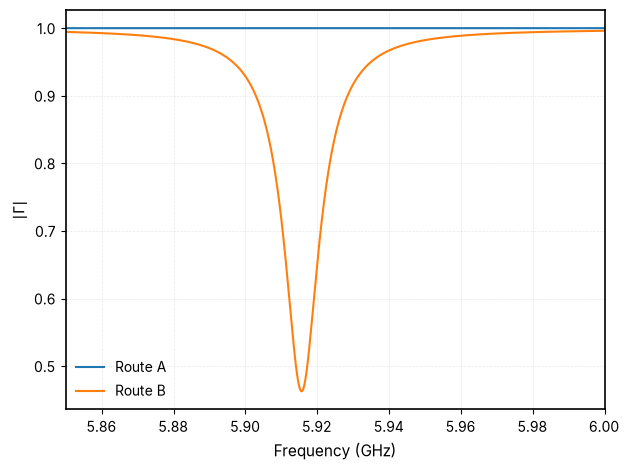

In [13]:
fig, ax = plt.subplots()
for route in "AB":
    ac = vacask.run(
        cpw_jpa_netlist(
            'analysis ac1 ac from=5.85e9 to=6.0e9 mode="lin" points=150001',
            route=route,
        )
    )["ac1"]
    f = jnp.asarray(ac["frequency"].real)
    gamma = reflection(ac["in"], I_SIG)
    f0, delay_width = resonance(f, gamma)
    metric = "κ/2π" if route == "A" else "4/(2π τ_peak)"
    print(
        f"Route {route}: f0 = {f0 / 1e9:.5f} GHz, {metric} = {delay_width / 1e6:.2f} MHz, "
        f"min |Γ| = {jnp.abs(gamma).min():.3f}"
    )
    ax.plot(f / 1e9, jnp.abs(gamma), label=f"Route {route}")
ax.set_xlabel("Frequency (GHz)")
ax.set_ylabel(r"$|\Gamma|$")
ax.legend()
show_plot()

Route B gives min $|\Gamma|=0.463$ at resonance. Its $10^{-3}$ S-parameter
error introduces appreciable loss in a $Q\approx580$ resonator. Its
$4/(2\pi\tau_\text{peak})=9.08$ MHz is an effective group-delay quantity, not
a loaded linewidth. The lossless identity used for Route A no longer applies.
Use Route A, or tighten the fit near resonance, when the line sets amplifier
$Q$.

## Limitations

- **Classical.** HB gives classical gain and conversion. It does not give
  added noise or squeezing ({cite:t}`clerkIntroductionQuantumNoise2010`;
  {cite:t}`royIntroductionParametricAmplification2016`). The junction shunt
  conductance is noiseless.
- **Threshold and stability.** The single-mode threshold comes from AC scans.
  It assumes a purely phase-modulated resonance. `hbac` linearizes around the
  pumped state whether or not it is stable. Above threshold the reported gain
  is not physical.
- **Route B fit loss.** A $10^{-3}$ rational fit adds appreciable loss in this
  $Q\approx580$ resonator. Its group delay cannot be read as a lossless
  linewidth. The fit covers 10 MHz to 70 GHz.
- **Multimode gain.** Eq. {eq}`eq:vacask-3wm-gain` ignores the higher line
  modes, so it overestimates the gain of this resonator. Its threshold is
  also only an estimate. A design that needs single-mode behaviour should
  detune the $3\lambda/4$ mode from $3f_0$, for example with a larger
  SQUID participation or a stepped-impedance line.
- **Junction and SQUID models.** RCSJ keeps only the first Josephson harmonic
  {cite:p}`McCumber1968,tinkhamIntroductionSuperconductivity2015`; real
  junctions show higher ones
  {cite:p}`willschObservationJosephsonHarmonics2024`. The SQUID model
  neglects loop inductance and asymmetry.

## References

```{bibliography}
:filter: docname in docnames
```